# من $Ax=b$ إلى المربعات الصغرى
## A practical linear algebra notebook

هذا الدفتر ينظّم تجاربك الأصلية باستخدام **NumPy وSciPy وSymPy وMatplotlib**، ويربط الحساب بالهندسة. احتُفظ بالمصفوفات والمتجهات والتجارب الأساسية، مع جمع الخطوات المرتبطة، وإضافة الشرح والتحقق العددي، ومعالجة الأخطاء التعليمية دون إيقاف الدفتر.

**الهدف:** فهم متى يوجد حل، وكيف تصف النواة جميع الحلول، ولماذا يقود التعامد إلى الإسقاط والمربعات الصغرى.

### خريطة الدفتر / Contents

1. [الإعداد وطريقة التشغيل](#setup)
2. [حل نظام قابل للعكس](#exact-system)
3. [مصفوفة منفردة وحلول غير وحيدة](#singular-system)
4. [الفضاءات الأساسية الأربعة والتعامد](#subspaces)
5. [المحدد والتحويلات الهندسية](#determinants)
6. [إسقاط متجه على خط](#line-projection)
7. [المربعات الصغرى والإسقاط على مستوى](#least-squares)
8. [عندما يكون المتجه داخل فضاء الأعمدة](#exact-projection)
9. [الملخص العربي الشامل](#arabic-summary)
10. [Comprehensive English summary](#english-summary)

**الرموز:** $A\in\mathbb R^{m\times n}$ مصفوفة، و$x\in\mathbb R^n$ معاملات الحل، و$b\in\mathbb R^m$ المتجه المطلوب. الرمز `@` يعني ضرب المصفوفات أو الضرب الداخلي بين متجهين أحاديي البعد؛ أما `*` في NumPy فيعني الضرب عنصرًا بعنصر.

<a id="setup"></a>
## 1. الإعداد وطريقة التشغيل / Setup

شغّل خلية الإعداد أولًا. بعد ذلك، كل خلية تجربة تعرّف مدخلاتها وتعيد حساب نتائجها داخل الخلية نفسها؛ لا تعتمد تجربة على قيمة تركتها تجربة سابقة. يعتمد الجميع فقط على مكتبات الإعداد و`ATOL` و`RTOL`.

لإعادة إنتاج النتائج، استخدم **Restart Kernel and Run All Cells**. تعديل قيمة مكتوبة في خلية لا يغيّر القيمة الموجودة في الذاكرة قبل تشغيلها، ولا يعيد تشغيل الخلايا التابعة تلقائيًا. لذلك غيّر المدخلات داخل خلية التجربة وأعد تشغيل الخلية كاملة.

المكتبات المطلوبة: `numpy scipy sympy matplotlib`، مع بيئة Jupyter ذات Python 3. يمكن تثبيتها عند الحاجة باستخدام `%pip install numpy scipy sympy matplotlib` في خلية مؤقتة. تُعرض الإصدارات الفعلية أدناه لتوثيق بيئة التنفيذ.

نستخدم `np.allclose` بدل `==` للتحقق العددي. حدود السماح هنا مناسبة للأمثلة الصغيرة في هذا الدفتر، وليست معيارًا عامًا لكل أحجام البيانات. في المقارنة مع الصفر، `ATOL` هو الحد المؤثر لأن الحد النسبي مضروب في صفر.

In [1]:
import sys
import warnings

import numpy as np
import scipy
import scipy.linalg as sc
import sympy as sp
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

ATOL = 1e-10
RTOL = 1e-10

print("Python:", sys.version.split()[0])
for name, module in [("NumPy", np), ("SciPy", scipy), ("SymPy", sp),
                     ("Matplotlib", matplotlib)]:
    print(f"{name}: {module.__version__}")
print(f"Comparison tolerances: atol={ATOL:g}, rtol={RTOL:g}")

Python: 3.12.13
NumPy: 2.5.4
SciPy: 1.18.1
SymPy: 1.14.0
Matplotlib: 3.11.2
Comparison tolerances: atol=1e-10, rtol=1e-10


<a id="exact-system"></a>
## 2. حل نظام قابل للعكس / A unique solution

نبدأ بالمصفوفة والمتجه الأصليين:

$$A=\begin{bmatrix}1&2&1\\2&5&3\\1&3&3\end{bmatrix},\qquad
b=\begin{bmatrix}4\\10\\7\end{bmatrix}.$$

نريد معاملات $x$ التي تجعل $Ax=b$. تستخدم `np.linalg.solve` لمصفوفة **مربعة وغير منفردة**؛ لا حاجة إلى حساب $A^{-1}$ صراحةً. نطبع $x$ ثم نعيد ضربه في $A$ للتحقق من النتيجة، بدل الاكتفاء بظهور أرقام من دالة الحل.

In [2]:
A_exact = np.array([[1, 2, 1], [2, 5, 3], [1, 3, 3]])
b_exact = np.array([4, 10, 7])
x_exact = np.linalg.solve(A_exact, b_exact)

print("A =\n", A_exact)
print("b:", b_exact)
print("x:", x_exact)
print("A @ x:", A_exact @ x_exact)
print("Rank:", np.linalg.matrix_rank(A_exact))
print("Determinant:", np.linalg.det(A_exact))
print("Residual norm:", np.linalg.norm(b_exact - A_exact @ x_exact))
assert np.allclose(x_exact, [1, 1, 1], atol=ATOL, rtol=RTOL)
assert np.allclose(A_exact @ x_exact, b_exact, atol=ATOL, rtol=RTOL)

A =
 [[1 2 1]
 [2 5 3]
 [1 3 3]]
b: [ 4 10  7]
x: [1. 1. 1.]
A @ x: [ 4. 10.  7.]
Rank: 3
Determinant: 1.0
Residual norm: 0.0


**النتيجة:** $x=(1,1,1)^T$، أي إن $b$ يساوي مجموع الأعمدة الثلاثة. رتبة $A$ تساوي $3$ ومحددها $1$، ولذلك الحل وحيد. متجه الباقي $b-Ax$ يساوي صفرًا رياضيًا، وقد يظهر أثر تقريبي صغير في الحساب العشري.

<a id="singular-system"></a>
## 3. المصفوفة المنفردة والحلول غير الوحيدة / Singular systems
### 3.1 لماذا تفشل `solve`؟

في تجربتك الثانية:

$$A_2=\begin{bmatrix}1&2&3\\2&4&6\\1&1&1\end{bmatrix},\qquad
b_2=\begin{bmatrix}6\\12\\3\end{bmatrix}.$$

الصف الثاني ضعف الأول، ولذلك الصفوف غير مستقلة. نحتفظ بمحاولة `solve` بوصفها تجربة تعليمية، ونلتقط الخطأ المتوقع حتى يستمر التشغيل. الفشل يعني عدم توافر حل وحيد بهذه الطريقة؛ **لا يعني وحده عدم وجود أي حل**.

نقارن رتبة $A_2$ برتبة المصفوفة الموسعة $[A_2\mid b_2]$. تساوي الرتبتين يعني اتساق النظام، وإذا كانت الرتبة أصغر من عدد المجهولات فالحلول غير وحيدة.

In [3]:
A_2 = np.array([[1, 2, 3], [2, 4, 6], [1, 1, 1]])
b_2 = np.array([6, 12, 3])

try:
    x_2 = np.linalg.solve(A_2, b_2)
except np.linalg.LinAlgError as exc:
    print("Expected solve failure:", exc)

rank_A2 = np.linalg.matrix_rank(A_2)
rank_augmented = np.linalg.matrix_rank(np.column_stack((A_2, b_2)))
print("Rank(A_2):", rank_A2)
print("Rank([A_2 | b_2]):", rank_augmented)
print("Determinant:", np.linalg.det(A_2))
print("Consistent:", rank_A2 == rank_augmented)
print("Number of free variables:", A_2.shape[1] - rank_A2)
assert rank_A2 == rank_augmented == 2

Expected solve failure: Singular matrix
Rank(A_2): 2
Rank([A_2 | b_2]): 2
Determinant: 0.0
Consistent: True
Number of free variables: 1


**النتيجة:** الرتبتان $2$، وعدد المجهولات $3$؛ إذن هناك متغير حر واحد وحلول لا نهائية. لو زادت رتبة المصفوفة الموسعة عن رتبة $A$ لكان النظام غير متسق. للمصفوفات المربعة فقط، المحدد الصفري يدل على التفرد؛ في الحساب العشري، فحص الرتبة والقيم المفردة أدق عمليًا من اتخاذ قرار اعتمادًا على محدد قريب من الصفر فقط.

### 3.2 هل يغيّر استخدام LU وجود الحل؟ / The LU experiment

تجربتك الأصلية استخدمت `sc.lu_solve(sc.lu_factor(A_2), b_2)`. تبديل المكتبة لا يزيل اعتماد الصفوف. قد تصدر `lu_factor` تحذيرًا عن محور صفري، ثم تنتج خطوة الحل قيمًا غير صالحة مثل `nan` أو `inf`.

نحوّل التحذير الخاص بالتفرد إلى استثناء **داخل هذه المحاولة فقط**، ونحافظ على تسلسل التحليل ثم الحل إذا نجح التحليل. لا نعرض ناتجًا غير صالح على أنه حل.

In [4]:
A_2_lu = np.array([[1, 2, 3], [2, 4, 6], [1, 1, 1]], dtype=float)
b_2_lu = np.array([6, 12, 3], dtype=float)

try:
    with warnings.catch_warnings():
        warnings.simplefilter("error", sc.LinAlgWarning)
        lu_factors = sc.lu_factor(A_2_lu)
        x_2_sc = sc.lu_solve(lu_factors, b_2_lu)
    print("LU candidate:", x_2_sc)
    print("Finite:", np.isfinite(x_2_sc).all())
    print("Satisfies system:", np.allclose(A_2_lu @ x_2_sc, b_2_lu,
                                           atol=ATOL, rtol=RTOL))
except (sc.LinAlgWarning, np.linalg.LinAlgError) as exc:
    print("Expected LU failure for a singular matrix:", exc)
    print("Use the symbolic solution below to describe all solutions.")

Expected LU failure for a singular matrix: Diagonal number 3 is exactly zero. Singular matrix.
Use the symbolic solution below to describe all solutions.


### 3.3 الحل الرمزي العام / A symbolic family of solutions

نستخدم SymPy للحساب الدقيق بدل التقريب العشري. تُرجع `gauss_jordan_solve` متجه الحل ومعاملاته الحرة. أسماء المعاملات مثل `tau0` أسماء آلية؛ يمكن أن نسمّي المعامل $t$ دون تغيير المعنى.

نتوقع:

$$x=\begin{bmatrix}t\\3-2t\\t\end{bmatrix}
=\underbrace{\begin{bmatrix}0\\3\\0\end{bmatrix}}_{x_p}
+t\underbrace{\begin{bmatrix}1\\-2\\1\end{bmatrix}}_{v}.$$

In [5]:
A_sym = sp.Matrix([[1, 2, 3], [2, 4, 6], [1, 1, 1]])
b_sym = sp.Matrix([6, 12, 3])
solution, parameters = A_sym.gauss_jordan_solve(b_sym)

print("General solution:")
display(solution)
print("Free parameters:")
display(parameters)
print("Exact symbolic residual:")
display(sp.simplify(A_sym * solution - b_sym))
assert A_sym * solution == b_sym

General solution:


Matrix([
[      tau0],
[3 - 2*tau0],
[      tau0]])

Free parameters:


Matrix([[tau0]])

Exact symbolic residual:


Matrix([
[0],
[0],
[0]])

### 3.4 حل خاص واتجاه النواة / Particular solution and null direction

احتُفظ بالحل الخاص `S = [0, 3, 0]` ومتجه النواة `[1, -2, 1]`. نتحقق من $A_2S=b_2$ و$A_2v=0$، ثم نجرّب عدة قيم للمعامل. نجاح العينات توضيح عددي، أما سبب صحة الصيغة لكل $t$ فهو:

$$A_2(S+tv)=A_2S+tA_2v=b_2+t0=b_2.$$

In [6]:
A_family = np.array([[1, 2, 3], [2, 4, 6], [1, 1, 1]])
b_family = np.array([6, 12, 3])
S = np.array([0, 3, 0])
v_null = np.array([1, -2, 1])

print("A @ S:", A_family @ S)
print("b:", b_family)
print("A @ v:", A_family @ v_null)
for parameter in [-2, 0, 0.5, 3]:
    candidate = S + parameter * v_null
    print(f"t={parameter:4}: x={candidate}, A @ x={A_family @ candidate}")
    assert np.allclose(A_family @ candidate, b_family, atol=ATOL, rtol=RTOL)
assert np.allclose(A_family @ v_null, 0, atol=ATOL, rtol=RTOL)

A @ S: [ 6 12  3]
b: [ 6 12  3]
A @ v: [0 0 0]
t=  -2: x=[-2  7 -2], A @ x=[ 6 12  3]
t=   0: x=[0 3 0], A @ x=[ 6 12  3]
t= 0.5: x=[0.5 2.  0.5], A @ x=[ 6. 12.  3.]
t=   3: x=[ 3 -3  3], A @ x=[ 6 12  3]


### 3.5 رسم مجموعة الحلول / The affine solution line

نرسم $x_p+tv$ في **فضاء المجهولات** $(x_1,x_2,x_3)$. هذا خط مزاح عن الأصل؛ أما $N(A_2)$ فهو الخط الموازي له والمار بالأصل. متجه النواة الأخضر يوضّح الاتجاه، والنقطة الحمراء حل خاص. العرض يرسم جزءًا محدودًا فقط من خط الحلول اللانهائي.

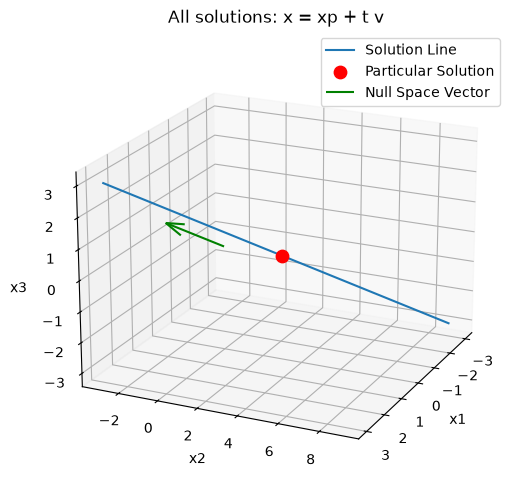

In [7]:
import numpy as np
import matplotlib.pyplot as plt

xp = np.array([0, 3, 0])
v_solution = np.array([1, -2, 1])

t = np.linspace(-3, 3, 100)

# All solutions of Ax = b
solutions = xp + t[:, None] * v_solution

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

# Draw the solution line
ax.plot(solutions[:, 0], solutions[:, 1], solutions[:, 2], label="Solution Line")

# Draw the particular solution
ax.scatter(*xp, color="red", s=80, label="Particular Solution")

# Draw the null space direction
ax.quiver(0, 0, 0, *v_solution, color="green", label="Null Space Vector")

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("x3")

ax.set_title("All solutions: x = xp + t v")
ax.view_init(elev=20, azim=25)
ax.legend()
plt.show()

**الفكرة:** مجموعة حلول $Ax=b$ المتسق هي $x_p+N(A)$، وليست النواة نفسها إلا إذا كان $b=0$. جميع النقاط على خط الحلول تنتقل بواسطة $A_2$ إلى المتجه نفسه $b_2$.

<a id="subspaces"></a>
## 4. الفضاءات الأساسية الأربعة / Four fundamental subspaces
### 4.1 القواعد والأبعاد / Bases and dimensions

نستخدم $A_3=A_2$ كما في تجربتك. إذا كانت $A\in\mathbb R^{m\times n}$ ورتبتها $r$:

| الفضاء / Space | التعريف | الفضاء المحيط | البعد |
|---|---|---|---|
| فضاء الأعمدة $C(A)$ | جميع تراكيب أعمدة $A$ | $\mathbb R^m$ | $r$ |
| فضاء الصفوف $C(A^T)$ | جميع تراكيب صفوف $A$ | $\mathbb R^n$ | $r$ |
| النواة $N(A)$ | المتجهات التي تحقق $Ax=0$ | $\mathbb R^n$ | $n-r$ |
| النواة اليسرى $N(A^T)$ | المتجهات التي تحقق $A^Ty=0$ | $\mathbb R^m$ | $m-r$ |

القوائم التي تعيدها SymPy هي **قواعد** للفضاءات، وليست جميع عناصر الفضاء. قد تختلف القاعدة باختلاف الطريقة مع بقاء الفضاء نفسه. تعيد `rowspace()` متجهات على هيئة صفوف.

In [8]:
A_3 = np.array([[1, 2, 3], [2, 4, 6], [1, 1, 1]])
A_3_Sym = sp.Matrix(A_3)
bases = {
    "Column Space": A_3_Sym.columnspace(),
    "Row Space": A_3_Sym.rowspace(),
    "Null Space": A_3_Sym.nullspace(),
    "Left Null Space": A_3_Sym.T.nullspace(),
}
for name, basis in bases.items():
    print(f"{name} basis:")
    display(basis)
    print(f"{name} Dimension: {len(basis)}")

m_sub, n_sub = A_3_Sym.shape
r_sub = A_3_Sym.rank()
assert len(bases["Column Space"]) == len(bases["Row Space"]) == r_sub == 2
assert r_sub + len(bases["Null Space"]) == n_sub
assert r_sub + len(bases["Left Null Space"]) == m_sub

Column Space basis:


[Matrix([
 [1],
 [2],
 [1]]),
 Matrix([
 [2],
 [4],
 [1]])]

Column Space Dimension: 2
Row Space basis:


[Matrix([[1, 2, 3]]), Matrix([[0, -1, -2]])]

Row Space Dimension: 2
Null Space basis:


[Matrix([
 [ 1],
 [-2],
 [ 1]])]

Null Space Dimension: 1
Left Null Space basis:


[Matrix([
 [-2],
 [ 1],
 [ 0]])]

Left Null Space Dimension: 1


**النتيجة:** الأبعاد بالترتيب $2,2,1,1$. لفضاء الأعمدة قاعدة مثل $(1,2,1)^T,(2,4,1)^T$؛ وللنواة قاعدة $(1,-2,1)^T$؛ وللنواة اليسرى قاعدة $(-2,1,0)^T$. قاعدة فضاء الصفوف قد تظهر بصفوف مكافئة من الاختزال، وليس بالضرورة بصفوف $A$ الأصلية.

### 4.2 اختبار التعامد وتصحيح معنى الضرب / Orthogonality and matrix shapes

العلاقتان الصحيحتان هما:

$$C(A)\perp N(A^T),\qquad C(A^T)\perp N(A).$$

في الخلية الأصلية، `u @ v.T` لمتجهين عموديين بحجم $3\times1$ ينتج **مصفوفة $3\times3$ (حاصل ضرب خارجي)**، وليس عددًا يقيس التعامد. نحتفظ بهذه المقارنة لتوضيح الفرق، ثم نستخدم `u.dot(v)` أو $u^Tv$ للضرب الداخلي. اختلاف الأشكال مهم حتى عندما لا يعطي البرنامج خطأ.

اختبار متجه واحد من المستوى لا يكفي لإثبات التعامد مع المستوى كله؛ لذلك نفحص جميع أزواج متجهات القواعد المناسبة بحساب رمزي دقيق.

In [9]:
A_orth = sp.Matrix([[1, 2, 3], [2, 4, 6], [1, 1, 1]])
u_col = A_orth.columnspace()[0]
v_left = A_orth.T.nullspace()[0]

print("Outer product u @ v.T; shape:", (u_col @ v_left.T).shape)
display(u_col @ v_left.T)
print("Inner product u.dot(v):", u_col.dot(v_left))
print("Inner product (u.T @ v)[0, 0]:", (u_col.T @ v_left)[0, 0])

column_left_dots = sp.Matrix([
    [u.dot(v) for v in A_orth.T.nullspace()]
    for u in A_orth.columnspace()
])
row_null_dots = sp.Matrix([
    [u.dot(v) for v in A_orth.nullspace()]
    for u in A_orth.rowspace()
])
print("All column-basis / left-null-basis inner products:")
display(column_left_dots)
print("All row-basis / null-basis inner products:")
display(row_null_dots)
assert column_left_dots == sp.zeros(*column_left_dots.shape)
assert row_null_dots == sp.zeros(*row_null_dots.shape)

Outer product u @ v.T; shape: (3, 3)


Matrix([
[-2, 1, 0],
[-4, 2, 0],
[-2, 1, 0]])

Inner product u.dot(v): 0
Inner product (u.T @ v)[0, 0]: 0
All column-basis / left-null-basis inner products:


Matrix([
[0],
[0]])

All row-basis / null-basis inner products:


Matrix([
[0],
[0]])

### 4.3 مستوى الأعمدة واتجاه عمودي / A plane and its normal

في $\mathbb R^3$ يولّد العمودان المستقلان $u=(1,2,1)^T$ و$v=(2,4,1)^T$ مستوى. الضرب الاتجاهي `np.cross(u, v)` يعطي $n=(-2,1,0)^T$، وهو متجه عمودي على كليهما، ولذلك على المستوى كله، وينتمي إلى $N(A_3^T)$.

الضرب الاتجاهي هنا أداة خاصة بالأبعاد الثلاثة، وليس بديلًا عامًا لحساب النواة. إذا كان المتجهان غير مستقلين فقد يعطي المتجه الصفري، الذي لا يحدّد اتجاهًا عموديًا.

Normal Vector: [-2  1  0]
u dot n: 0
v dot n: 0
A.T @ n: [0 0 0]


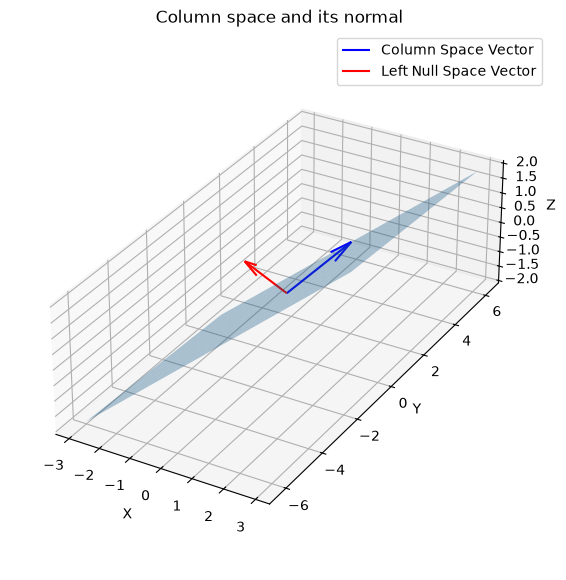

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Basis vectors of the Column Space
u_plane = np.array([1, 2, 1])
v_plane = np.array([2, 4, 1])

# Normal vector to the plane
n_plane = np.cross(u_plane, v_plane)

print("Normal Vector:", n_plane)
print("u dot n:", np.dot(u_plane, n_plane))
print("v dot n:", np.dot(v_plane, n_plane))
A_normal = np.array([[1, 2, 3], [2, 4, 6], [1, 1, 1]])
print("A.T @ n:", A_normal.T @ n_plane)
assert np.allclose(A_normal.T @ n_plane, 0, atol=ATOL, rtol=RTOL)

# Generate the plane
s, t = np.meshgrid(np.linspace(-1, 1, 15), np.linspace(-1, 1, 15))

plane = s[..., None] * u_plane + t[..., None] * v_plane

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

# Column Space
ax.plot_surface(plane[:, :, 0], plane[:, :, 1], plane[:, :, 2], alpha=0.35)

# Vector in Column Space
ax.quiver(0, 0, 0, *u_plane, color="blue", label="Column Space Vector")

# Vector in Left Null Space
ax.quiver(0, 0, 0, *n_plane, color="red", label="Left Null Space Vector")

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

ax.set_box_aspect([np.ptp(ax.get_xlim()), np.ptp(ax.get_ylim()), np.ptp(ax.get_zlim())])
ax.set_title("Column space and its normal")
ax.legend()

plt.show()

**قراءة الرسم:** السطح هو جزء من فضاء الأعمدة، والسهم الأحمر اتجاه النواة اليسرى. المنظور ثلاثي الأبعاد قد لا يُظهر زاوية قائمة على الشاشة؛ التحقق الحاسم هو $A^Tn=0$، وليس الانطباع البصري وحده.

<a id="determinants"></a>
## 5. المحدد والتحويلات الهندسية / Determinants and geometry

نحتفظ بتجاربك الأربع على مربع الوحدة. أعمدة المصفوفة هي صور متجهي الأساس، وصورة المربع تكون متوازي أضلاع أو شكلًا منهارًا. في بعدين:

$$\text{مساحة الصورة}=|\det A|\times\text{المساحة الأصلية}.$$

إشارة المحدد تبيّن حفظ التوجّه أو عكسه. المحدد السالب لا يعني مساحة سالبة، و$\det A=1$ لا يعني أن المصفوفة هي الهوية أو أنها تحفظ الأطوال والزوايا.

المربع مخزّن على هيئة **نقاط صفية**؛ لذلك `square @ A.T` يطبق التحويل نفسه الذي تكتبه $Ax$ عند تمثيل كل نقطة كمتجه عمودي.

### 5.1 تمديد وقص / Scaling and shear

$A=\begin{bmatrix}2&1\\0&3\end{bmatrix}$، ومحددها $6$. نتوقع مساحة تساوي ستة أمثال مساحة مربع الوحدة، مع حفظ التوجّه.

Determinant: 6.0
Area Scale Factor: 6.0
Rank: 2


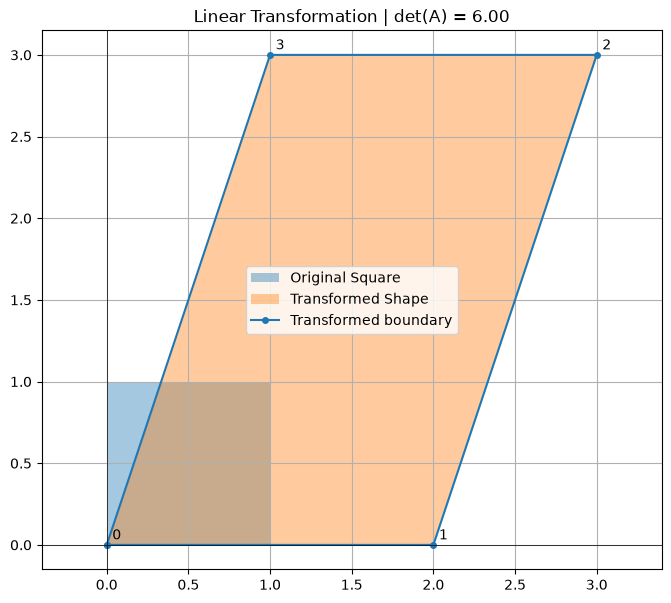

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Transformation Matrix
A_scale = np.array([[2, 1], [0, 3]])

# Original Unit Square
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]])

# Apply Linear Transformation
transformed = square @ A_scale.T

# Calculate Determinant
det = np.linalg.det(A_scale)

print("Determinant:", round(det, 6))
print("Area Scale Factor:", abs(det))

assert np.isclose(det, 6, atol=ATOL, rtol=RTOL)
print("Rank:", np.linalg.matrix_rank(A_scale))

# Visualization
plt.figure(figsize=(8, 7))

plt.fill(square[:, 0], square[:, 1], alpha=0.4, label="Original Square")

plt.fill(transformed[:, 0], transformed[:, 1], alpha=0.4, label="Transformed Shape")

plt.plot(transformed[:, 0], transformed[:, 1], "o-", markersize=4,
         label="Transformed boundary")
for vertex_id, point in enumerate(transformed[:-1]):
    plt.annotate(str(vertex_id), point, xytext=(4, 4), textcoords="offset points")

plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.title(f"Linear Transformation | det(A) = {det:.2f}")

plt.show()

**النتيجة:** المحدد $6$، والمساحة $6$. العنصر خارج القطر يميل الشكل، لذلك لا يكفي وصف التحويل بأنه تمديد قطري فقط.

### 5.2 انهيار إلى خط / Collapse to a line

$A=\begin{bmatrix}2&4\\1&2\end{bmatrix}$، وعمودها الثاني ضعف الأول. نتوقع رتبة $1$، ومحددًا ومساحة يساويان صفرًا.

Determinant: 0.0
Area Scale Factor: 0.0
Rank: 1


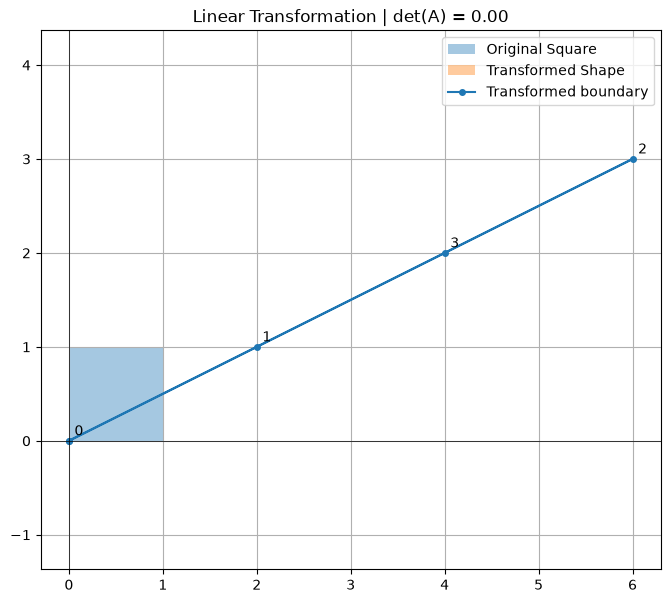

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Transformation Matrix
A_collapse = np.array([[2, 4], [1, 2]])

# Original Unit Square
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]])

# Apply Linear Transformation
transformed = square @ A_collapse.T

# Calculate Determinant
det = np.linalg.det(A_collapse)

print("Determinant:", round(det, 6))
print("Area Scale Factor:", abs(det))

assert np.isclose(det, 0, atol=ATOL, rtol=RTOL)
print("Rank:", np.linalg.matrix_rank(A_collapse))

# Visualization
plt.figure(figsize=(8, 7))

plt.fill(square[:, 0], square[:, 1], alpha=0.4, label="Original Square")

plt.fill(transformed[:, 0], transformed[:, 1], alpha=0.4, label="Transformed Shape")

plt.plot(transformed[:, 0], transformed[:, 1], "o-", markersize=4,
         label="Transformed boundary")
for vertex_id, point in enumerate(transformed[:-1]):
    plt.annotate(str(vertex_id), point, xytext=(4, 4), textcoords="offset points")

plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.title(f"Linear Transformation | det(A) = {det:.2f}")

plt.show()

**النتيجة:** صورة المربع تقع على الخط المولّد بـ$(2,1)^T$. قد لا يظهر تعبئة للشكل لأن مساحته صفر؛ أُضيف رسم حدوده ونقاطه لإظهار الانهيار.

### 5.3 عكس التوجّه / Reversing orientation

$A=\begin{bmatrix}0&2\\3&0\end{bmatrix}$، ومحددها $-6$. نتوقع مساحة $6$ مع عكس التوجّه.

Determinant: -6.0
Area Scale Factor: 6.0
Rank: 2


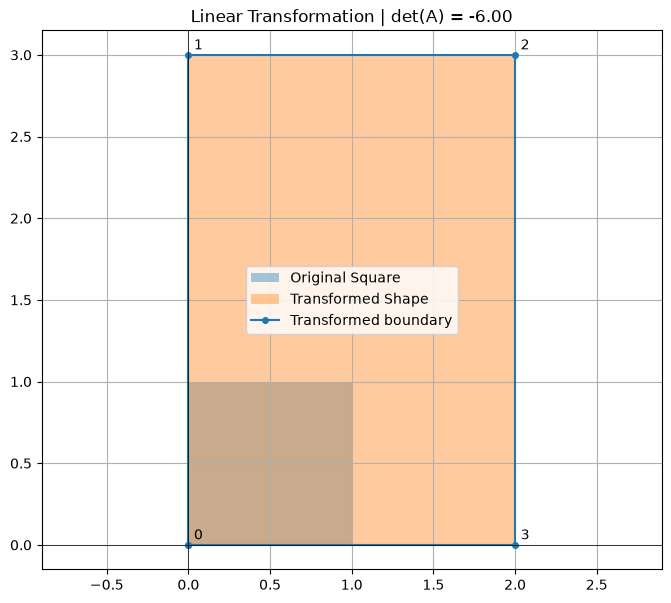

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Transformation Matrix
A_flip = np.array([[0, 2], [3, 0]])

# Original Unit Square
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]])

# Apply Linear Transformation
transformed = square @ A_flip.T

# Calculate Determinant
det = np.linalg.det(A_flip)

print("Determinant:", round(det, 6))
print("Area Scale Factor:", abs(det))

assert np.isclose(det, -6, atol=ATOL, rtol=RTOL)
print("Rank:", np.linalg.matrix_rank(A_flip))

# Visualization
plt.figure(figsize=(8, 7))

plt.fill(square[:, 0], square[:, 1], alpha=0.4, label="Original Square")

plt.fill(transformed[:, 0], transformed[:, 1], alpha=0.4, label="Transformed Shape")

plt.plot(transformed[:, 0], transformed[:, 1], "o-", markersize=4,
         label="Transformed boundary")
for vertex_id, point in enumerate(transformed[:-1]):
    plt.annotate(str(vertex_id), point, xytext=(4, 4), textcoords="offset points")

plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.title(f"Linear Transformation | det(A) = {det:.2f}")

plt.show()

**النتيجة:** مساحة الصورة $6$ رغم أن المحدد $-6$. تتبّع ترتيب الرؤوس المتناظرة لرؤية تغيّر التوجّه؛ التلوين وحده لا يبرهنه.

### 5.4 قص يحفظ المساحة / Area-preserving shear

$A=\begin{bmatrix}1&2\\0&1\end{bmatrix}$؛ أي $(x,y)\mapsto(x+2y,y)$. نتوقع محددًا $1$ مع تغير شكل المربع.

Determinant: 1.0
Area Scale Factor: 1.0
Rank: 2


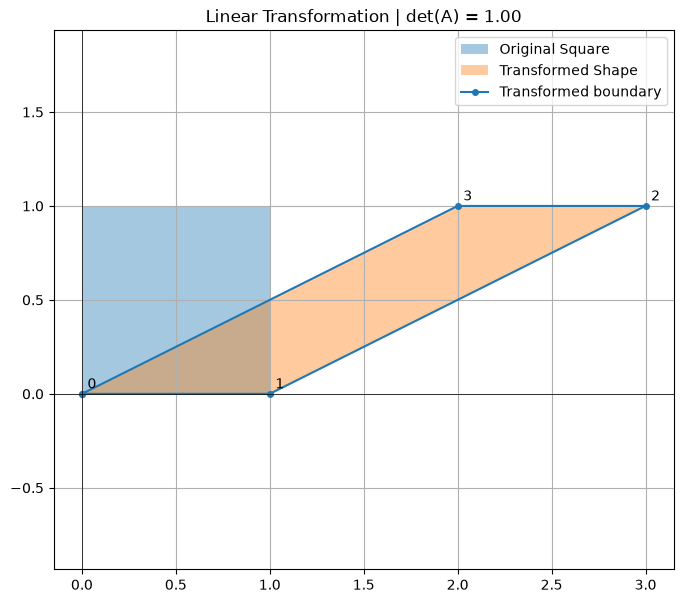

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Transformation Matrix
A_shear = np.array([[1, 2], [0, 1]])

# Original Unit Square
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]])

# Apply Linear Transformation
transformed = square @ A_shear.T

# Calculate Determinant
det = np.linalg.det(A_shear)

print("Determinant:", round(det, 6))
print("Area Scale Factor:", abs(det))

assert np.isclose(det, 1, atol=ATOL, rtol=RTOL)
print("Rank:", np.linalg.matrix_rank(A_shear))

# Visualization
plt.figure(figsize=(8, 7))

plt.fill(square[:, 0], square[:, 1], alpha=0.4, label="Original Square")

plt.fill(transformed[:, 0], transformed[:, 1], alpha=0.4, label="Transformed Shape")

plt.plot(transformed[:, 0], transformed[:, 1], "o-", markersize=4,
         label="Transformed boundary")
for vertex_id, point in enumerate(transformed[:-1]):
    plt.annotate(str(vertex_id), point, xytext=(4, 4), textcoords="offset points")

plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.title(f"Linear Transformation | det(A) = {det:.2f}")

plt.show()

**النتيجة:** المساحة والتوجّه محفوظان، لكن بعض الأطوال والزوايا تتغير. حفظ المساحة لا يساوي حفظ الشكل.

<a id="line-projection"></a>
## 6. إسقاط متجه على خط / Projection onto a line

نعود إلى متجهي تجربتك: $a=(2,1)^T$ و$b=(1,3)^T$. الخط المطلوب هو $\operatorname{Span}(a)$ والمار بالأصل. نريد أقرب نقطة $p=\alpha a$ إلى $b$.

من شرط $a^T(b-\alpha a)=0$ نحصل على:

$$\alpha=\frac{a^Tb}{a^Ta},\qquad p=\frac{a^Tb}{a^Ta}a,\qquad e=b-p.$$

الصيغة تتطلب $a\ne0$. نتوقع $p=(2,1)^T$ و$e=(-1,2)^T$. نضع حساب الإسقاط والرسم والأطوال في خلية واحدة حتى يتحدّث الجميع معًا عند تغيير المدخلات.

نرسم $e$ من رأس $p$ إلى رأس $b$ لإظهار $b=p+e$. **التعامد يعتمد على الاتجاه لا على موضع رسم السهم**؛ نقل السهم إلى الأصل لا يغيّر متجهَه أو تعامده.

Projection: [2. 1.]
Error: [-1.  2.]
Dot Product: 0.0


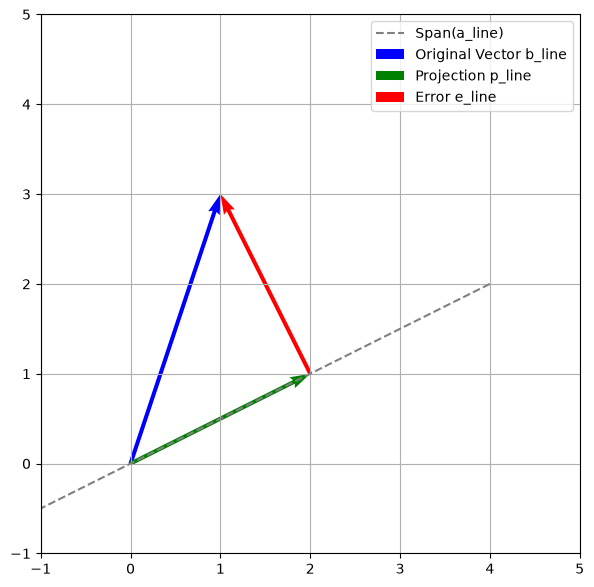

Length of b_line: 3.1622776601683795
Length of p_line: 2.23606797749979
Length of e_line: 2.23606797749979
Pythagorean identity: 10.000000000000002 = 10.000000000000002


In [15]:
import numpy as np

a_line = np.array([2, 1])
b_line = np.array([1, 3])

assert a_line @ a_line > 0, "Projection direction must be nonzero."

# Projection of b_line onto a_line
p_line = (a_line @ b_line / (a_line @ a_line)) * a_line

# Error vector
e_line = b_line - p_line

print("Projection:", p_line)
print("Error:", e_line)
print("Dot Product:", p_line @ e_line)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 7))

# Line generated by a_line
t = np.linspace(-1, 2, 100)
line = t[:, None] * a_line

ax.plot(line[:, 0], line[:, 1], "--", color="gray", label="Span(a_line)")

# Original vector b_line
ax.quiver(
    0,
    0,
    *b_line,
    angles="xy",
    scale_units="xy",
    scale=1,
    color="blue",
    label="Original Vector b_line"
)

# Projection vector p_line
ax.quiver(
    0,
    0,
    *p_line,
    angles="xy",
    scale_units="xy",
    scale=1,
    color="green",
    label="Projection p_line"
)

# Error vector e_line: from p_line to b_line
ax.quiver(*p_line, *e_line, angles="xy", scale_units="xy", scale=1, color="red", label="Error e_line")

ax.set_xlim(-1, 5)
ax.set_ylim(-1, 5)
ax.set_aspect("equal")

ax.grid(True)
ax.legend()
plt.show()

print("Length of b_line:", np.linalg.norm(b_line))
print("Length of p_line:", np.linalg.norm(p_line))
print("Length of e_line:", np.linalg.norm(e_line))

print("Pythagorean identity:", np.linalg.norm(b_line)**2,
      "=", np.linalg.norm(p_line)**2 + np.linalg.norm(e_line)**2)
assert np.allclose(a_line @ e_line, 0, atol=ATOL, rtol=RTOL)
assert np.allclose(b_line, p_line + e_line, atol=ATOL, rtol=RTOL)
assert np.isclose(np.linalg.norm(b_line)**2,
                  np.linalg.norm(p_line)**2 + np.linalg.norm(e_line)**2,
                  atol=ATOL, rtol=RTOL)

**النتيجة:** $a^Te=0$ و$p^Te=0$. الأطوال هي $\|b\|=\sqrt{10}$ و$\|p\|=\|e\|=\sqrt5$، ولذلك $10=5+5$. التعامد يجعل المسافة أقصر: لأي نقطة أخرى $q$ على الخط،

$$\|b-q\|^2=\|e\|^2+\|p-q\|^2\ge\|e\|^2.$$

هذا هو السبب الهندسي لأمثلية الإسقاط، وليس مجرد قاعدة حسابية.

<a id="least-squares"></a>
## 7. الإسقاط على مستوى والمربعات الصغرى / Least squares

نستخدم مصفوفتك المستطيلة:

$$A=\begin{bmatrix}1&0\\1&1\\1&2\end{bmatrix},\qquad
b=\begin{bmatrix}1\\2\\2\end{bmatrix}.$$

أعمدة $A$ مستقلة وتولّد مستوى داخل $\mathbb R^3$. المتجه $b$ خارج هذا المستوى، ولذلك لا يمكن تحقيق $Ax=b$ تمامًا. نبحث بدل ذلك عن:

$$\hat x=\arg\min_x\|Ax-b\|_2^2,\qquad p=A\hat x,\qquad e=b-p.$$

**ميّز بين $\hat x\in\mathbb R^2$ (معاملات) و$p\in\mathbb R^3$ (أقرب متجه داخل فضاء الأعمدة).** وبما أن العمودين هما $(1,1,1)^T$ و$(0,1,2)^T$، يمكن أيضًا فهم التجربة على أنها ملاءمة خط للقيم $1,2,2$ عند $t=0,1,2$؛ معاملَا الحل هما المقطع والميل.

شرط الأمثلية هو:

$$A^Te=0\quad\Longleftrightarrow\quad A^TA\hat x=A^Tb.$$

هذه هي المعادلات الطبيعية. عندما تكون الأعمدة مستقلة يمكن كتابة $\hat x=(A^TA)^{-1}A^Tb$ نظريًا، لكننا نحسب باستخدام `np.linalg.lstsq`؛ تكوين $A^TA$ وحساب معكوسه صراحةً قد يضاعف صعوبة التكييف العددي. حتى مع اعتماد الأعمدة، يظل الإسقاط $p$ وحيدًا؛ قد لا تكون المعاملات وحيدة، وتعيد `lstsq` حلًا بأصغر معيار إقليدي وفق الرتبة العددية المستخدمة.

x_hat_ls: [1.16666667 0.5       ]
Projection: [1.16666667 1.66666667 2.16666667]
Error: [-0.16666667  0.33333333 -0.16666667]
A_ls.T @ e_ls: [1.99840144e-15 1.77635684e-15]
p_ls @ e_ls: 3.2751579226442118e-15
Projection equals b (within tolerance): False
Error magnitude: 0.4082482904638629
Pythagorean check: True


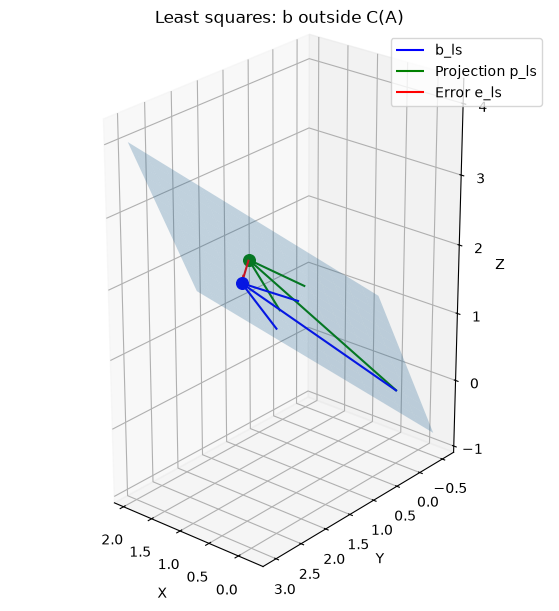

In [16]:
import numpy as np

A_ls = np.array([[1, 0], [1, 1], [1, 2]])

b_ls = np.array([1, 2, 2])

# Least Squares solution
x_hat_ls = np.linalg.lstsq(A_ls, b_ls, rcond=None)[0]

# Projection onto Column Space
p_ls = A_ls @ x_hat_ls

# Error vector
e_ls = b_ls - p_ls

print("x_hat_ls:", x_hat_ls)
print("Projection:", p_ls)
print("Error:", e_ls)

print("A_ls.T @ e_ls:", A_ls.T @ e_ls)
print("p_ls @ e_ls:", p_ls @ e_ls)

print("Projection equals b (within tolerance):", np.allclose(p_ls, b_ls, atol=ATOL, rtol=RTOL))
print("Error magnitude:", np.linalg.norm(e_ls))


print("Pythagorean check:", np.isclose(b_ls @ b_ls,
                                      p_ls @ p_ls + e_ls @ e_ls,
                                      atol=ATOL, rtol=RTOL))
assert np.allclose(x_hat_ls, [7/6, 1/2], atol=ATOL, rtol=RTOL)
assert np.allclose(p_ls, [7/6, 5/3, 13/6], atol=ATOL, rtol=RTOL)
assert np.allclose(e_ls, [-1/6, 1/3, -1/6], atol=ATOL, rtol=RTOL)
assert np.allclose(A_ls.T @ e_ls, 0, atol=ATOL, rtol=RTOL)
assert np.isclose(np.linalg.norm(e_ls), np.sqrt(1/6), atol=ATOL, rtol=RTOL)


# Generate the Column Space plane
s, t = np.meshgrid(np.linspace(-0.25, 2, 15), np.linspace(-0.25, 1, 15))

plane = s[..., None] * A_ls[:, 0] + t[..., None] * A_ls[:, 1]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# Column Space
ax.plot_surface(plane[:, :, 0], plane[:, :, 1], plane[:, :, 2], alpha=0.25)

# Original vector
ax.quiver(0, 0, 0, *b_ls, color="blue", label="b_ls")

# Projection
ax.quiver(0, 0, 0, *p_ls, color="green", label="Projection p_ls")

# Error: from p_ls to b_ls
ax.quiver(*p_ls, *e_ls, color="red", label="Error e_ls")

ax.scatter(*p_ls, color="green", s=70)
ax.scatter(*b_ls, color="blue", s=70)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

ax.set_title("Least squares: b outside C(A)")
ax.view_init(elev=25, azim=130)
ax.set_box_aspect([np.ptp(ax.get_xlim()), np.ptp(ax.get_ylim()), np.ptp(ax.get_zlim())])
ax.legend()
plt.show()

**النتائج المتوقعة وتفسيرها:**

$$\hat x=\begin{bmatrix}7/6\\1/2\end{bmatrix},\quad
p=\begin{bmatrix}7/6\\5/3\\13/6\end{bmatrix},\quad
e=\begin{bmatrix}-1/6\\1/3\\-1/6\end{bmatrix},\quad
\|e\|=\sqrt{1/6}\approx0.408248.$$

المتجه الأزرق خارج المستوى، والأخضر هو الإسقاط، والأحمر من رأس $p$ إلى رأس $b$. الباقي عمودي على **كل أعمدة $A$**، وليس على $p$ وحده: $e\in N(A^T)$ و$p\in C(A)$. وبالتالي $b=p+e$ هو تحليل إلى جزأين متعامدين.

قد تظهر قيم مثل $10^{-15}$ بدل الصفر في $A^Te$ أو $p^Te$ بسبب دقة الأعداد العائمة. أما $0.408248$ فمسافة غير صفرية فعلًا، وليست خطأ تقريب عائم. **الرسم وحده لا يثبت انطباق $p$ على $b$**؛ نتحقق من الحسابات ومن مقدار الباقي.

<a id="exact-projection"></a>
## 8. عندما يكون $b$ داخل فضاء الأعمدة / Exact projection

الآن نُبقي المصفوفة نفسها ونستخدم $b=(1,1,1)^T$، وهو عمودها الأول. إذن نعرف مسبقًا أن $b\in C(A)$، وأن حلًا دقيقًا هو $x=(1,0)^T$.

هذا هو الموضع الذي ظهرت فيه مشكلة القيم القديمة في المحادثة: تغيير `b` وحده ثم طباعة `p` و`e` السابقين يُبقي مسافة التجربة السابقة ظاهرة. لذلك تُعرّف هذه الخلية المصفوفة والمتجه وتعيد حساب **كل** من $\hat x,p,e$ معًا، بأسماء منفصلة عن تجربة الحالة غير المتسقة.

In [17]:
A_inside = np.array([[1, 0], [1, 1], [1, 2]])

b_inside = np.array([1, 1, 1])

x_hat_inside = np.linalg.lstsq(A_inside, b_inside, rcond=None)[0]

p_inside = A_inside @ x_hat_inside
e_inside = b_inside - p_inside

print("x_hat_inside:", x_hat_inside)
print("Projection:", p_inside)
print("Error:", e_inside)

print("Projection equals b (within tolerance):", np.allclose(p_inside, b_inside, atol=ATOL, rtol=RTOL))
print("Error magnitude:", np.linalg.norm(e_inside))

assert np.allclose(x_hat_inside, [1, 0], atol=ATOL, rtol=RTOL)
assert np.allclose(p_inside, b_inside, atol=ATOL, rtol=RTOL)
assert np.allclose(e_inside, 0, atol=ATOL, rtol=RTOL)
assert np.allclose(A_inside.T @ e_inside, 0, atol=ATOL, rtol=RTOL)

x_hat_inside: [1.00000000e+00 6.40987562e-17]
Projection: [1. 1. 1.]
Error: [3.33066907e-16 2.22044605e-16 2.22044605e-16]
Projection equals b (within tolerance): True
Error magnitude: 4.577566798522237e-16


**النتيجة:** $\hat x\approx(1,0)^T$، و$p\approx b$، و$\|e\|$ قريب جدًا من الصفر. قد تختلف آخر الخانات العشرية حسب الإصدارات والمنصة؛ ليس مطلوبًا الحصول على مقدار الخطأ نفسه حرفيًا كما في المحادثة.

رياضيًا:

$$b\in C(A)\iff Ax=b\text{ متسق}\iff p=b\iff e=0.$$

`allclose=True` يعني تقاربًا ضمن حدود السماح، ولا يبرهن مساواة رمزية تامة. هنا نعرف الاتساق أيضًا من كون $b$ أحد أعمدة $A$. ويمكن استخدام المربعات الصغرى حتى عند وجود حل دقيق؛ عندها يكون الحد الأدنى للباقي صفرًا.

### ملاحظات التنفيذ والتعديلات / Reproducibility notes

- جُمعت الخلايا الصغيرة المترابطة مع الحفاظ على مدخلات التجارب الأصلية وحساباتها ورسوماتها الأساسية.
- استُخدمت أسماء منفصلة للأنظمة والإسقاطات؛ كل خلية تجربة قابلة للتشغيل بعد خلية الإعداد دون تشغيل تجارب أخرى.
- بقيت محاولتا `solve` وLU للمصفوفة المنفردة كتجربتين تعليميتين مع معالجة الخطأ المتوقع.
- وُضّح أن `u @ v.T` حاصل ضرب خارجي، وأُضيف فحص التعامد لكل أزواج القواعد المناسبة.
- أُضيفت حدود الشكل المنهار وترقيم رؤوس المربعات لتسهيل قراءة تجارب المحدد، وضُبط مدى مستوى المربعات الصغرى لإظهار الباقي بوضوح أكبر.
- حُذفت المخرجات القديمة وأُعيد توليد المخرجات بالتنفيذ من نواة جديدة. تعليمات `assert` تتحقق من العلاقات الرياضية للأمثلة الحالية، وقد تحتاج تحديثًا إذا غيّرت بيانات التجربة عمدًا. لا تُحذف لمجرد جعل نتيجة خاطئة تمرّ.

للتجربة بنفسك: غيّر $b$ في خلية واحدة، وتوقّع أولًا إن كان في فضاء الأعمدة، ثم أعد تشغيل الخلية كاملة وقارن بين توقعك ومقدار الباقي و$A^Te$. إذا غيّرت قيمًا كثيرًا، قد تحتاج أيضًا إلى توسيع حدود الرسم.

<a id="arabic-summary"></a>
## 9. الملخص العربي الشامل

### أ. ماذا يعني $Ax=b$؟

ضرب $A$ في $x$ يعني تكوين تركيب خطي من أعمدة $A$ بأوزان هي عناصر $x$. لذلك يوجد حل دقيق إذا وفقط إذا كان $b$ داخل فضاء الأعمدة $C(A)$. في المثال الأول كان الحل الوحيد $(1,1,1)^T$ لأن المصفوفة مربعة ورتبتها كاملة.

إذا كانت $r=\operatorname{rank}(A)$، فقاعدة تصنيف الحلول هي:

| الشرط | النتيجة |
|---|---|
| $\operatorname{rank}([A\mid b])>r$ | لا يوجد حل دقيق |
| $\operatorname{rank}([A\mid b])=r=n$ | حل دقيق وحيد |
| $\operatorname{rank}([A\mid b])=r<n$ | حلول لا نهائية، وعدد المتغيرات الحرة $n-r$ |

المصفوفة المنفردة لا تملك معكوسًا. فشل `solve` أو LU لا يخبرك وحده إن كان النظام غير متسق أم ذا حلول لا نهائية؛ افحص الرتب أو الحل الرمزي. في تجربتنا المنفردة كانت الرتبتان $2$، فوجد متغير حر واحد.

### ب. كيف نصف جميع الحلول؟

إذا كان $x_p$ حلًا خاصًا، فكل الحلول هي $x=x_p+z$ حيث $z\in N(A)$. في المثال:

$$x=\begin{bmatrix}0\\3\\0\end{bmatrix}
+t\begin{bmatrix}1\\-2\\1\end{bmatrix},\qquad t\in\mathbb R.$$

النواة تحقق $Az=0$ وتمر بالأصل. خط حلول النظام غير المتجانس خط مزاح موازٍ للنواة. المتجهات $x$ في هذا الرسم تنتمي إلى فضاء المجهولات، وليست نقاطًا في فضاء الأعمدة لمجرد أن المثالين ثلاثيا الأبعاد.

### ج. الفضاءات الأربعة والتعامد

لـ$A\in\mathbb R^{m\times n}$ ورتبة $r$:

- $C(A)\subseteq\mathbb R^m$ وبعده $r$؛ هو جميع المخرجات الممكنة $Ax$.
- $C(A^T)\subseteq\mathbb R^n$ وبعده $r$؛ هو فضاء الصفوف.
- $N(A)\subseteq\mathbb R^n$ وبعده $n-r$؛ اتجاهات لا تغيّر المخرج عند إضافتها إلى المدخل.
- $N(A^T)\subseteq\mathbb R^m$ وبعده $m-r$؛ متجهات متعامدة مع جميع أعمدة $A$.

$$C(A)\perp N(A^T),\qquad C(A^T)\perp N(A).$$

في المثال ذي الرتبة $2$ كانت الأبعاد $2,2,1,1$. لتأكيد أن متجهًا عمودي على مستوى، افحص ضربه الداخلي مع قاعدة المستوى كاملة. للمتجهات العمودية الرمزية، استخدم `.dot()` أو $u^Tv$؛ أما $uv^T$ فهو مصفوفة خارجية.

### د. ماذا يشرح المحدد؟

المحدد للمصفوفات المربعة. في بعدين، $|\det A|$ عامل تغيير المساحة، وإشارته تحدد حفظ التوجّه أو عكسه. تجاربنا أعطت:

| التجربة | المحدد | المعنى |
|---|---:|---|
| تمديد مع قص | $6$ | مساحة تتضاعف ست مرات وتوجّه محفوظ |
| أعمدة معتمدة | $0$ | انهيار المربع إلى خط، ومساحة صفرية |
| عكس التوجّه مع تمديد | $-6$ | مساحة $6$ وتوجّه معكوس |
| قص | $1$ | مساحة محفوظة مع تغير الشكل |

المحدد $1$ لا يضمن حفظ الأطوال أو الزوايا. وفي الحساب العشري لا تعتمد على مقارنة المحدد بالصفر وحدها لتشخيص مصفوفة قريبة من التفرد.

### هـ. الإسقاط والمربعات الصغرى

على خط مولّد بمتجه غير صفري $a$:

$$p=\frac{a^Tb}{a^Ta}a,\qquad e=b-p,\qquad a^Te=0.$$

في مثال $a=(2,1)^T,b=(1,3)^T$ حصلنا على $p=(2,1)^T,e=(-1,2)^T$. رسم الباقي من رأس الإسقاط يوضح جمع المتجهات؛ موضع السهم لا يغيّر التعامد.

للإسقاط على فضاء الأعمدة عمومًا:

$$\hat x=\arg\min_x\|Ax-b\|^2,\quad p=A\hat x,\quad e=b-p,\quad A^Te=0.$$

المعاملات $\hat x$ تعيش في $\mathbb R^n$، بينما $p,b,e$ تعيش في $\mathbb R^m$. الإسقاط $p$ وحيد دائمًا، لكن $\hat x$ يكون وحيدًا فقط إذا كانت الأعمدة مستقلة. المعادلات الطبيعية $A^TA\hat x=A^Tb$ تشرح شرط التعامد؛ عمليًا نستخدم `np.linalg.lstsq` بدل تكوين المعكوس صراحةً.

لـ$A=\begin{bmatrix}1&0\\1&1\\1&2\end{bmatrix}$:

| المتجه $b$ | $\hat x$ | الإسقاط $p$ | الباقي $e$ | $\|e\|$ |
|---|---|---|---|---|
| $(1,2,2)^T$ | $(7/6,1/2)^T$ | $(7/6,5/3,13/6)^T$ | $(-1/6,1/3,-1/6)^T$ | $\sqrt{1/6}\approx0.408248$ |
| $(1,1,1)^T$ | $(1,0)^T$ | $b$ | $0$ | $0$ رياضيًا |

هذا يربط الفضاءات بالإسقاط:

$$b=p+e,\quad p\in C(A),\quad e\in N(A^T),\quad
\|b\|^2=\|p\|^2+\|e\|^2.$$

ولأي $q\in C(A)$، فإن $\|b-q\|^2=\|e\|^2+\|p-q\|^2$؛ لذلك $p$ أقرب نقطة. إذا كان $b\in C(A)$ فالحد الأدنى للباقي صفر، وإلا فهو موجب.

### و. ما الذي يجب تذكره عند العودة إلى الدفتر؟

1. شغّل الإعداد، ثم التجربة كاملة؛ وللتحقق الشامل استخدم **Restart Kernel and Run All Cells**.
2. عند تغيير المدخلات أعد حساب النتائج التابعة؛ القيم القديمة لا تتحدّث تلقائيًا.
3. فرّق بين خطأ فعلي مثل $0.408248$ وأثر تقريبي صغير مثل $10^{-15}$.
4. `np.allclose` مقارنة ضمن سماح، وليست برهانًا رمزيًا. اختر السماح بحسب مقياس البيانات وحساسية المسألة.
5. استعمل SymPy للنتائج الدقيقة، وNumPy/SciPy للحساب العددي؛ الرسم يساعد الفهم، والرتب والبواقي والضرب الداخلي تتحقق من الاستنتاجات.

<a id="english-summary"></a>
## 10. Comprehensive English summary

### A. What does $Ax=b$ mean?

$Ax$ is a linear combination of the columns of $A$, with coefficients taken from $x$. An exact solution exists **if and only if** $b\in C(A)$. The first experiment has the unique solution $x=(1,1,1)^T$: its square matrix has full rank and determinant $1$.

For $A\in\mathbb R^{m\times n}$ with rank $r$:

| Condition | Exact solution set |
|---|---|
| $\operatorname{rank}([A\mid b])>r$ | No solution |
| $\operatorname{rank}([A\mid b])=r=n$ | One solution |
| $\operatorname{rank}([A\mid b])=r<n$ | Infinitely many solutions; $n-r$ free variables |

`np.linalg.solve` expects a square, nonsingular matrix. A singular-matrix error does not distinguish inconsistency from infinitely many solutions. Switching to LU does not remove the mathematical singularity; heed its warning rather than treating nonfinite output as a solution. The singular example has coefficient and augmented rank $2$, so it is consistent with one free parameter.

### B. Particular solution plus null space

If $x_p$ is a particular solution, every solution is $x=x_p+z$ with $z\in N(A)$. Here:

$$x=\begin{bmatrix}0\\3\\0\end{bmatrix}
+t\begin{bmatrix}1\\-2\\1\end{bmatrix},\qquad t\in\mathbb R.$$

This works because $Ax_p=b$ and $Az=0$. The null space passes through the origin; the nonhomogeneous solution set is its translated, affine copy. The solution-line plot lives in the **input/coefficient space**, not the column space. SymPy describes the full family exactly; testing several parameter values illustrates the result but is not a proof for all values.

### C. Four fundamental subspaces

| Space | Meaning | Ambient space | Dimension |
|---|---|---|---|
| $C(A)$ | All possible outputs $Ax$ | $\mathbb R^m$ | $r$ |
| $C(A^T)$ | Row space | $\mathbb R^n$ | $r$ |
| $N(A)$ | Inputs satisfying $Ax=0$ | $\mathbb R^n$ | $n-r$ |
| $N(A^T)$ | Vectors orthogonal to every column of $A$ | $\mathbb R^m$ | $m-r$ |

The orthogonal pairs are $C(A)\perp N(A^T)$ and $C(A^T)\perp N(A)$. The example has dimensions $2,2,1,1$. SymPy returns a **basis**, not every vector in a space; different valid bases can describe the same space.

Check orthogonality against every vector in a spanning basis. For column matrices, $uv^T$ is an outer product, whereas $u^Tv$ is an inner product; `.dot()` also expresses the inner product. In the 3D example, the cross product of the two independent column vectors is $(-2,1,0)^T$, a left-null-space direction. A 3D viewing angle can distort apparent angles, so use dot products to verify the geometry.

### D. Determinants and geometry

Determinants apply to square matrices. In 2D, $|\det A|$ is the area scale factor; the sign tells whether orientation is preserved or reversed.

| Original transformation | Determinant | Finding |
|---|---:|---|
| Scaling with shear | $6$ | Area multiplied by $6$; orientation preserved |
| Dependent columns | $0$ | Unit square collapses onto a line |
| Orientation reversal with scaling | $-6$ | Area multiplied by $6$; orientation reversed |
| Shear | $1$ | Area preserved while shape changes |

A negative determinant is not a negative area. Determinant $1$ does not guarantee length or angle preservation. With floating-point data, rank/singular-value analysis is more useful than relying only on a near-zero determinant. The point arrays store row vectors, so `square @ A.T` implements the column-vector transformation $Ax$ for every point.

### E. Projection and least squares

For a line spanned by a **nonzero** vector $a$:

$$p=\frac{a^Tb}{a^Ta}a,\qquad e=b-p,\qquad a^Te=0.$$

For $a=(2,1)^T$ and $b=(1,3)^T$, the projection is $p=(2,1)^T$ and the residual is $e=(-1,2)^T$. Drawing $e$ from the tip of $p$ shows $b=p+e$; translating a vector does not change its direction or orthogonality.

For projection onto a general column space:

$$\hat x=\arg\min_x\|Ax-b\|_2^2,\quad p=A\hat x,\quad e=b-p.$$

Distinguish the coefficients $\hat x\in\mathbb R^n$ from the projected output $p\in\mathbb R^m$. The optimality condition is $A^Te=0$, equivalent to the normal equations $A^TA\hat x=A^Tb$. With independent columns, the coefficients are unique. With dependent columns, coefficients may be nonunique but the projection remains unique; `lstsq` returns a minimum-norm solution according to its numerical rank cutoff.

The inverse formula $(A^TA)^{-1}A^Tb$ requires independent columns. For numerical work, prefer `np.linalg.lstsq` over explicitly forming that inverse: forming $A^TA$ squares the 2-norm condition number for a full-column-rank matrix.

For $A=\begin{bmatrix}1&0\\1&1\\1&2\end{bmatrix}$:

| Target $b$ | Coefficients $\hat x$ | Projection $p$ | Residual $e$ | Residual norm |
|---|---|---|---|---|
| $(1,2,2)^T$ | $(7/6,1/2)^T$ | $(7/6,5/3,13/6)^T$ | $(-1/6,1/3,-1/6)^T$ | $\sqrt{1/6}\approx0.408248$ |
| $(1,1,1)^T$ | $(1,0)^T$ | $b$ | $0$ | $0$ mathematically |

The first column is constant and the second contains $0,1,2$, so the first case also fits a straight line to three observations: $\hat x$ contains the intercept and slope.

The central connection is:

$$b=p+e,\qquad p\in C(A),\qquad e\in N(A^T),\qquad
\|b\|^2=\|p\|^2+\|e\|^2.$$

For any other $q\in C(A)$, Pythagoras gives $\|b-q\|^2=\|e\|^2+\|p-q\|^2$. Thus $p$ is the closest vector in the column space. If $b$ already belongs to it, least squares attains zero residual and recovers an exact solution.

### F. Reliable notebook habits

1. Run setup first. Each experiment cell then defines its own inputs and recomputes its results; use **Restart Kernel and Run All Cells** for a complete reproducibility check.
2. Editing `b` does not automatically update stored `x_hat`, `p`, or `e`. Re-run the entire experiment after changing an input.
3. Separate a genuine nonzero residual such as $0.408248$ from floating-point roundoff such as $10^{-15}$. Last digits can vary across platforms and library versions.
4. `np.allclose` checks tolerance-based agreement, not symbolic equality. Tolerances must reflect data scale and conditioning; comparing to zero is governed by the absolute tolerance.
5. Use SymPy for exact algebra and NumPy/SciPy for numerical computation. Use plots to understand and residuals, ranks, and inner products to verify. Assertions document the current examples and must be reconsidered when their inputs change.